In [1]:
from matplotlib import pyplot as plt
import scipy
import numpy as np
from scipy import sparse
import sys
sys.path.insert(0, '..')   # goes from paper_plots/fig_1_compQITE -> repo root
from modules import Hamiltonian as ham
from modules import PauliStrings
from modules import Evolution as evol
from matplotlib.lines import Line2D

In [2]:
color1="#0041FC"
color2="#FC9904"
color3="#7D7548"

In [3]:
from pathlib import Path

pareto_root = Path("pareto")
model_paths = {
    model_path.name: model_path
    for model_path in pareto_root.iterdir()
    if model_path.is_dir()
}


def lambda_from_folder(folder_name):
    encoded_lambda = folder_name.removeprefix("sparse_qite_lambda_")
    encoded_lambda = encoded_lambda.replace("em", "e-")
    encoded_lambda = encoded_lambda.replace("p", ".")
    return float(encoded_lambda)


pareto_data = {}
for model_name, model_path in sorted(model_paths.items()):
    lambda_values = []
    nonzero_counts = []

    for lambda_path in model_path.glob("sparse_qite_lambda_*/trajectory.npz"):
        trajectory = np.load(lambda_path, allow_pickle=True)
        lambda_values.append(lambda_from_folder(lambda_path.parent.name))
        nonzero_counts.append(np.count_nonzero(trajectory["a"]))

    sort_order = np.argsort(lambda_values)
    pareto_data[model_name] = {
        "lambdas": np.asarray(lambda_values)[sort_order],
        "nonzero_counts": np.asarray(nonzero_counts)[sort_order],
    }

In [4]:
H_Hei, Htrot = ham.Heisenberg_PBC(1,8,2,False)
E_Hei,V_Hei = np.linalg.eigh(H_Hei)
GS_Hei = V_Hei[:,0]
print(np.real(E_Hei)[0])
H_ord, Htrot = ham.TFIM(1,0.5,8,2,False)
E_ord,V_ord = np.linalg.eigh(H_ord)
GS_ord = V_ord[:,0]
print(E_ord[0])
H_dis, Htrot = ham.TFIM(0.5,1,8,2,False)
E_dis,V_dis = np.linalg.eigh(H_dis)
GS_dis = V_dis[:,0]
print(E_dis[0])

Heisenberg model with PBC and Hamiltonian pieces of locality T=2
Succesfull Troterization
The Trotterization consists of 8 terms with the starting qubit of each piece at [0, 1, 2, 3, 4, 5, 6, 7]
-14.60437363574871
-8.509082235140282
-8.509082235140271


In [5]:
ground_states = {
    "heisenberg": GS_Hei,
    "tfim_ord": GS_ord,
    "tfim_disord": GS_dis,
}

pareto_fidelity_data = {}
for model_name, model_path in sorted(model_paths.items()):
    lambda_values = []
    fidelities = []
    ground_state = ground_states[model_name]

    for lambda_path in model_path.glob("sparse_qite_lambda_*/states.npz"):
        states = sparse.load_npz(lambda_path).toarray()
        final_state = states[:, -1]
        lambda_values.append(lambda_from_folder(lambda_path.parent.name))
        fidelities.append(np.abs(np.vdot(ground_state, final_state)) ** 2)

    sort_order = np.argsort(lambda_values)
    pareto_fidelity_data[model_name] = {
        "lambdas": np.asarray(lambda_values)[sort_order],
        "fidelities": np.asarray(fidelities)[sort_order],
    }

In [6]:
qite_default_data = {}
for model_name, model_path in sorted(model_paths.items()):
    qite_default_path = model_path / "qite_default"
    trajectory = np.load(qite_default_path / "trajectory.npz", allow_pickle=True)
    states = sparse.load_npz(qite_default_path / "states.npz").toarray()

    final_state = states[:, -1]
    qite_default_data[model_name] = {
        "nonzero_count": np.count_nonzero(trajectory["a"]),
        "final_fidelity": np.abs(
            np.vdot(ground_states[model_name], final_state)
        ) ** 2,
    }

In [7]:
def pareto_front(x_values, y_values):
    """Return points that minimize both x and y, ordered left to right."""
    order = np.argsort(x_values)
    x_sorted = np.asarray(x_values)[order]
    y_sorted = np.asarray(y_values)[order]

    unique_x, first_indices = np.unique(x_sorted, return_index=True)
    minimum_y = np.minimum.reduceat(y_sorted, first_indices)

    front_x = []
    front_y = []
    best_y = np.inf
    for x_value, y_value in zip(unique_x, minimum_y):
        if y_value < best_y:
            front_x.append(x_value)
            front_y.append(y_value)
            best_y = y_value

    return np.asarray(front_x), np.asarray(front_y)

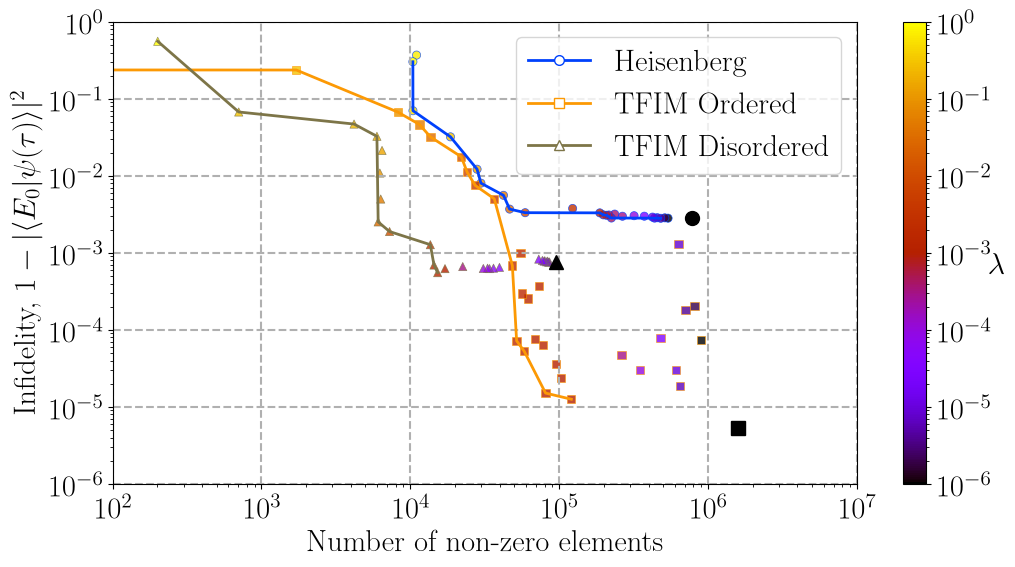

In [8]:
from matplotlib.colors import LogNorm

plt.figure(figsize=(12, 6))
plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)


pareto_front_data = {}
legend_handles = []
plot_data = {
    "heisenberg": ("Heisenberg", color1, "o"),
    "tfim_ord": ("TFIM Ordered", color2, "s"),
    "tfim_disord": ("TFIM Disordered", color3, "^"),
}

all_lambdas = np.concatenate([
    pareto_fidelity_data[model_name]["lambdas"]
    for model_name in plot_data
])
lambda_norm = LogNorm(vmin=all_lambdas.min(), vmax=all_lambdas.max())
lambda_cmap = "gnuplot"

for model_name, (label, color, marker) in plot_data.items():
    x_values = pareto_data[model_name]["nonzero_counts"]
    y_values = 1 - pareto_fidelity_data[model_name]["fidelities"]
    lambda_values = pareto_fidelity_data[model_name]["lambdas"]
    front_x, front_y = pareto_front(x_values, y_values)
    pareto_front_data[model_name] = {
        "nonzero_counts": front_x,
        "infidelities": front_y,
    }

    plt.scatter(
        x_values,
        y_values,
        c=lambda_values,
        cmap=lambda_cmap,
        norm=lambda_norm,
        marker=marker,
        edgecolors=color,
        linewidths=0.5,
        s=35,
        alpha=0.8,
    )
    plt.loglog(front_x, front_y, "-", color=color, linewidth=2)
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            linewidth=2,
            marker=marker,
            markersize=7,
            markerfacecolor="white",
            markeredgecolor=color,
            label=label,
        )
    )

lambda_mappable = plt.cm.ScalarMappable(norm=lambda_norm, cmap=lambda_cmap)
lambda_mappable.set_array([])
plot_axis = plt.gca()
lambda_colorbar = plt.colorbar(lambda_mappable, ax=plot_axis)
lambda_colorbar.set_label(r"$\lambda$", rotation=0)

plt.plot(qite_default_data["heisenberg"]["nonzero_count"], 1 - qite_default_data["heisenberg"]["final_fidelity"],
    "o", color='black', markersize=10)
plt.plot(qite_default_data["tfim_ord"]["nonzero_count"], 1 - qite_default_data["tfim_ord"]["final_fidelity"],
    "s", color='black', markersize=10)
plt.plot(qite_default_data["tfim_disord"]["nonzero_count"], 1 - qite_default_data["tfim_disord"]["final_fidelity"],
    "^", color='black', markersize=10)

plt.ylim(1e-6, 1)
plt.xlim(1e2, 1e7)
plt.xlabel("Number of non-zero elements")
plt.ylabel("Infidelity, $1-|\\langle E_0 | \\psi(\\tau) \\rangle|^2$")
plt.grid(linestyle = '--', linewidth = 1.5)
plt.legend(handles=legend_handles)
plt.savefig("pareto_plot.pdf", dpi=300, bbox_inches='tight')